<a href="https://colab.research.google.com/github/Sattvikannadatha/LLM-Ticket/blob/main/Employee_Turnover_analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Please upload the HR Employee Turnover dataset (.csv or .zip):


Saving 1736848217_hr_comma_sep.zip to 1736848217_hr_comma_sep (1).zip

--- 1. DATA QUALITY AUDIT ---
Missing values per column:
No missing values detected. Dataset is clean and ready.

--- 2.1 CORRELATION MATRIX (NUMERICAL FEATURES) ---


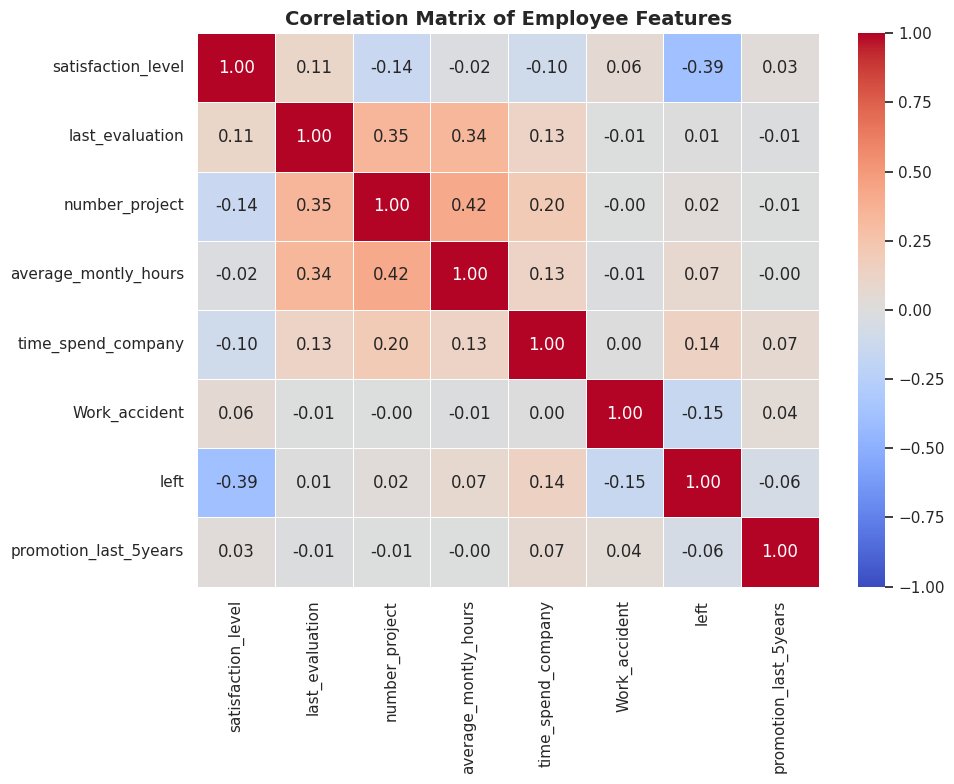


--- 2.2 FEATURE DISTRIBUTION PLOTS ---


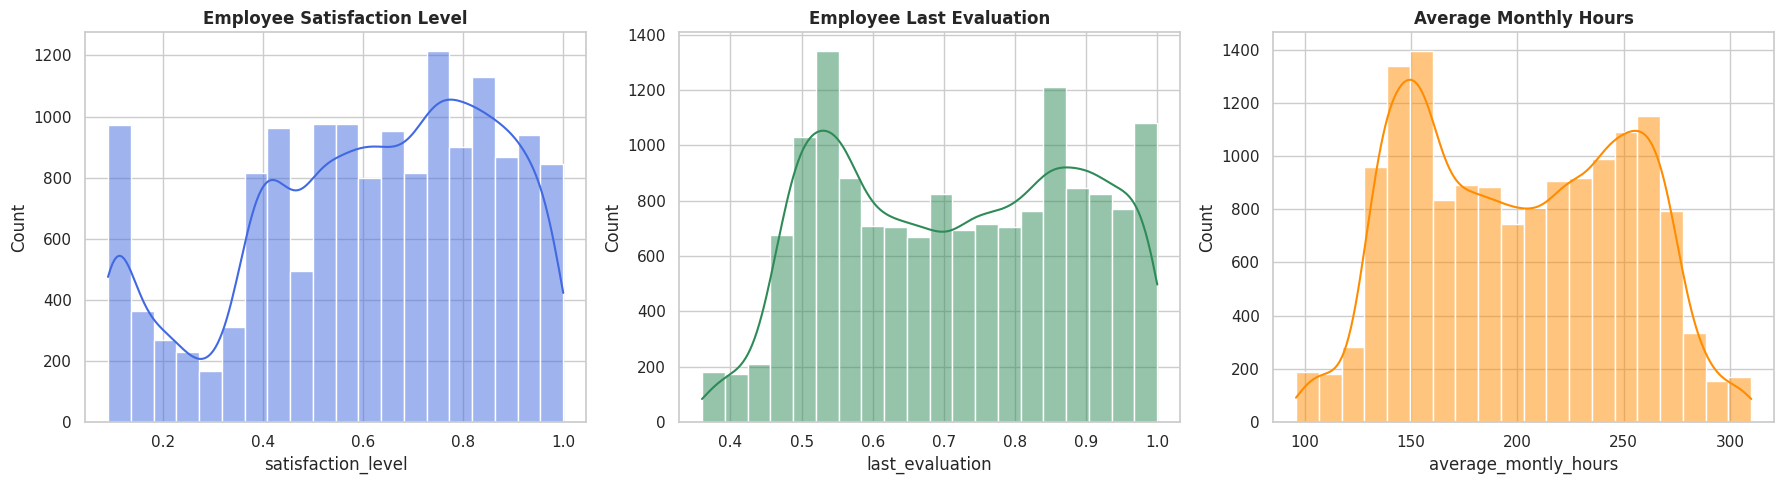


--- 2.3 PROJECT WORKLOAD VS TURNOVER ---


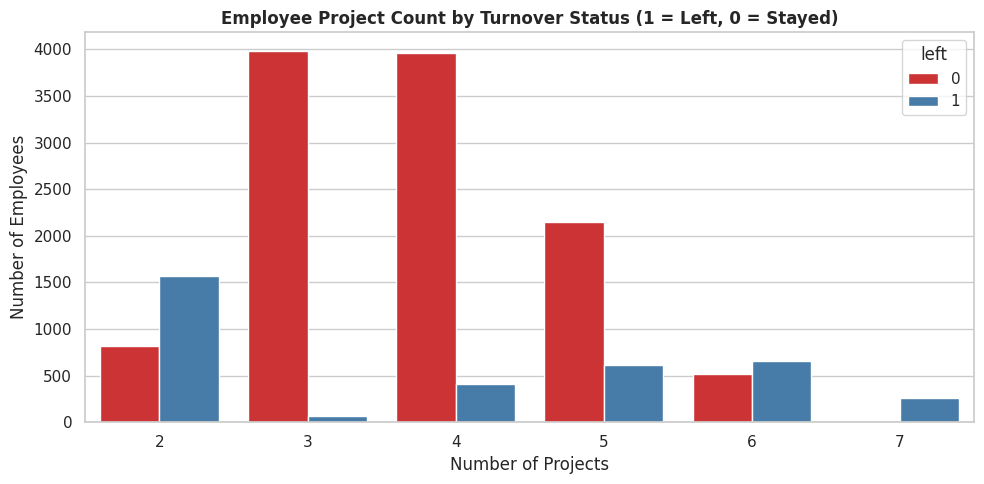


--- INFERENCES: PROJECT COUNT VS TURNOVER ---
- Underutilization/Boredom Risk: Employees assigned to only 2 projects show an extremely high turnover rate.
- The 'Sweet Spot': Employees with 3 to 4 projects show the highest retention and lowest turnover risk.
- Burnout Risk: Turnover spikes aggressively for employees with 6 or 7 projects, indicating severe overwork and systemic burnout.


In [ ]:
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import zipfile

sns.set_theme(style="whitegrid")

print("Please upload the HR Employee Turnover dataset (.csv or .zip):")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

# --- Handle Zip Extraction ---
if file_name.endswith('.zip'):
    with zipfile.ZipFile(io.BytesIO(uploaded[file_name]), 'r') as zf:
        csv_files = [f for f in zf.namelist() if f.endswith('.csv')]
        target_csv = csv_files[0]
        with zf.open(target_csv) as f:
            df = pd.read_csv(f)
else:
    df = pd.read_csv(io.BytesIO(uploaded[file_name]))

df.columns = df.columns.str.strip()

# --- 1. DATA QUALITY CHECKS ---
print("\n--- 1. DATA QUALITY AUDIT ---")
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.any() else "No missing values detected. Dataset is clean and ready.")

# --- 2.1 CORRELATION HEATMAP ---
print("\n--- 2.1 CORRELATION MATRIX (NUMERICAL FEATURES) ---")
plt.figure(figsize=(10, 8))
num_df = df.select_dtypes(include=[np.number])
sns.heatmap(num_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Employee Features', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

# --- 2.2 DISTRIBUTION PLOTS ---
print("\n--- 2.2 FEATURE DISTRIBUTION PLOTS ---")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['satisfaction_level'], bins=20, kde=True, color='royalblue', ax=axes[0])
axes[0].set_title('Employee Satisfaction Level', fontweight='bold')

sns.histplot(df['last_evaluation'], bins=20, kde=True, color='seagreen', ax=axes[1])
axes[1].set_title('Employee Last Evaluation', fontweight='bold')

sns.histplot(df['average_montly_hours'], bins=20, kde=True, color='darkorange', ax=axes[2])
axes[2].set_title('Average Monthly Hours', fontweight='bold')

plt.tight_layout()
plt.show()

# --- 2.3 PROJECT COUNT VS TURNOVER ---
print("\n--- 2.3 PROJECT WORKLOAD VS TURNOVER ---")
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='number_project', hue='left', palette='Set1')
plt.title('Employee Project Count by Turnover Status (1 = Left, 0 = Stayed)', fontweight='bold')
plt.xlabel('Number of Projects')
plt.ylabel('Number of Employees')
plt.tight_layout()
plt.show()

print("\n--- INFERENCES: PROJECT COUNT VS TURNOVER ---")
print("- Underutilization/Boredom Risk: Employees assigned to only 2 projects show an extremely high turnover rate.")
print("- The 'Sweet Spot': Employees with 3 to 4 projects show the highest retention and lowest turnover risk.")
print("- Burnout Risk: Turnover spikes aggressively for employees with 6 or 7 projects, indicating severe overwork and systemic burnout.")

--- 3. K-MEANS CLUSTERING (ATTRITION SEGMENTS) ---


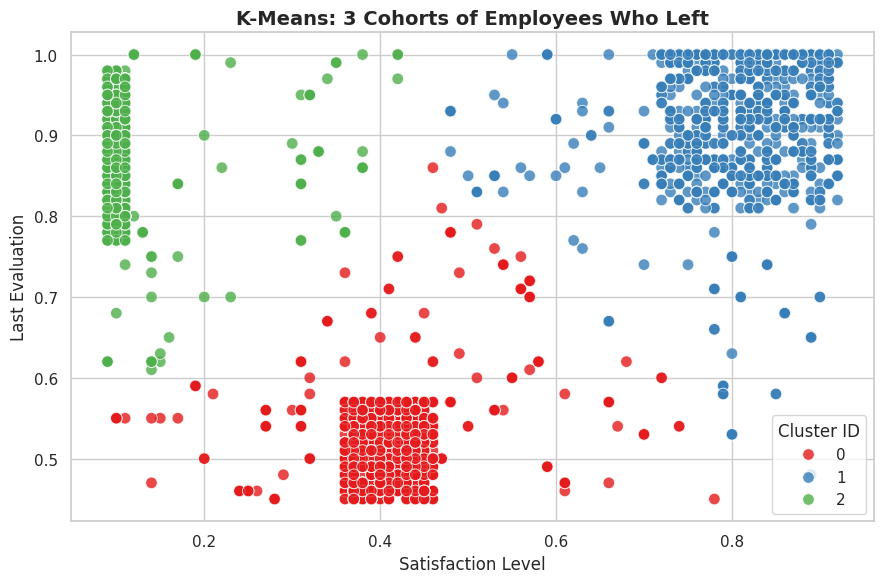


--- 3.3 CLUSTER INFERENCES (ATTRITION DRIVERS) ---
Based on the mathematical groupings of satisfaction and evaluation, we can define three exact turnover profiles:
1. The 'Burnout' Cohort (Low Satisfaction, High Evaluation): These are top performers who are overworked and exhausted. They are leaving due to extreme stress.
2. The 'Bad Fit' Cohort (Low Satisfaction, Low Evaluation): These employees are disengaged and underperforming. Their departure is likely mutual or beneficial.
3. The 'Poached' Cohort (High Satisfaction, High Evaluation): These are happy, high-tier talents. If they are leaving, they are likely being poached by competitors offering better salary/titles.

--- 4. DATA PREPROCESSING & HANDLING CLASS IMBALANCE ---
Original Training Class Distribution (Imbalanced):
left
0    9142
1    2857
Name: count, dtype: int64

SMOTE Training Class Distribution (Balanced):
left
0    9142
1    9142
Name: count, dtype: int64

Class imbalance successfully handled. Data matrix is ready fo

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# --- 3. CLUSTERING EMPLOYEES WHO LEFT (Steps 3.1 & 3.2) ---
print("--- 3. K-MEANS CLUSTERING (ATTRITION SEGMENTS) ---")
# Filter dataset for only employees who left
left_emp = df[df['left'] == 1].copy()
cluster_data = left_emp[['satisfaction_level', 'last_evaluation']]

# Execute K-Means for 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
left_emp['Cluster'] = kmeans.fit_predict(cluster_data)

# Visualize the 3 employee clusters
plt.figure(figsize=(9, 6))
sns.scatterplot(data=left_emp, x='satisfaction_level', y='last_evaluation', hue='Cluster', palette='Set1', s=70, alpha=0.8)
plt.title('K-Means: 3 Cohorts of Employees Who Left', fontweight='bold', fontsize=14)
plt.xlabel('Satisfaction Level')
plt.ylabel('Last Evaluation')
plt.legend(title='Cluster ID')
plt.tight_layout()
plt.show()

# --- 3.3 CLUSTER INFERENCES ---
print("\n--- 3.3 CLUSTER INFERENCES (ATTRITION DRIVERS) ---")
print("Based on the mathematical groupings of satisfaction and evaluation, we can define three exact turnover profiles:")
print("1. The 'Burnout' Cohort (Low Satisfaction, High Evaluation): These are top performers who are overworked and exhausted. They are leaving due to extreme stress.")
print("2. The 'Bad Fit' Cohort (Low Satisfaction, Low Evaluation): These employees are disengaged and underperforming. Their departure is likely mutual or beneficial.")
print("3. The 'Poached' Cohort (High Satisfaction, High Evaluation): These are happy, high-tier talents. If they are leaving, they are likely being poached by competitors offering better salary/titles.\n")

# --- 4. PREPROCESSING & SMOTE (Steps 4.1, 4.2, 4.3) ---
print("--- 4. DATA PREPROCESSING & HANDLING CLASS IMBALANCE ---")
# 4.1 Convert categorical columns to numerical using get_dummies (drop_first=True avoids multicollinearity)
cat_cols = df.select_dtypes(include=['object']).columns
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# Separate features (X) and target (y)
X = df_encoded.drop('left', axis=1)
y = df_encoded['left']

# 4.2 Stratified Train-Test Split (80:20 with random_state=123)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=123)

print("Original Training Class Distribution (Imbalanced):")
print(y_train.value_counts())

# 4.3 Upsample the minority class (turnover) using SMOTE
smote = SMOTE(random_state=123)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("\nSMOTE Training Class Distribution (Balanced):")
print(y_train_sm.value_counts())
print("\nClass imbalance successfully handled. Data matrix is ready for cross-validated model training.")

--- 5. MODEL TRAINING & CROSS-VALIDATION ---
Logistic Regression - 5-Fold CV Accuracy: 0.7950 (+/- 0.0333)

Classification Report for Logistic Regression:
              precision    recall  f1-score   support

           0       0.91      0.77      0.83      2286
           1       0.51      0.74      0.60       714

    accuracy                           0.77      3000
   macro avg       0.71      0.76      0.72      3000
weighted avg       0.81      0.77      0.78      3000

------------------------------------------------------------
Random Forest - 5-Fold CV Accuracy: 0.9837 (+/- 0.0027)

Classification Report for Random Forest:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2286
           1       0.98      0.98      0.98       714

    accuracy                           0.99      3000
   macro avg       0.99      0.99      0.99      3000
weighted avg       0.99      0.99      0.99      3000

--------------------------------

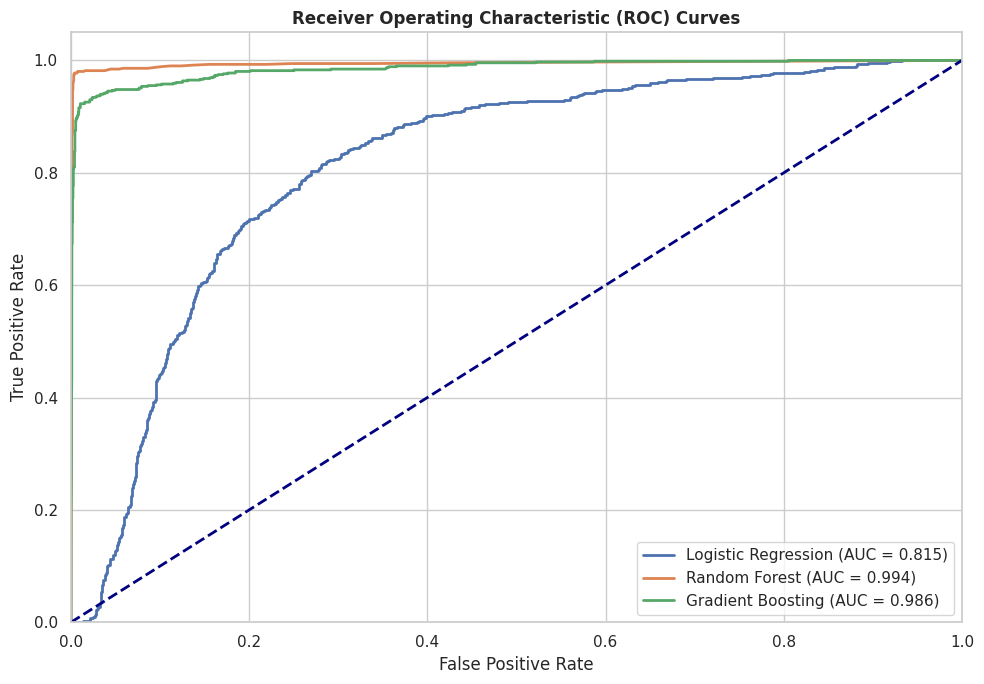


Best Model Identified: Random Forest (Highest AUC: 0.9945)


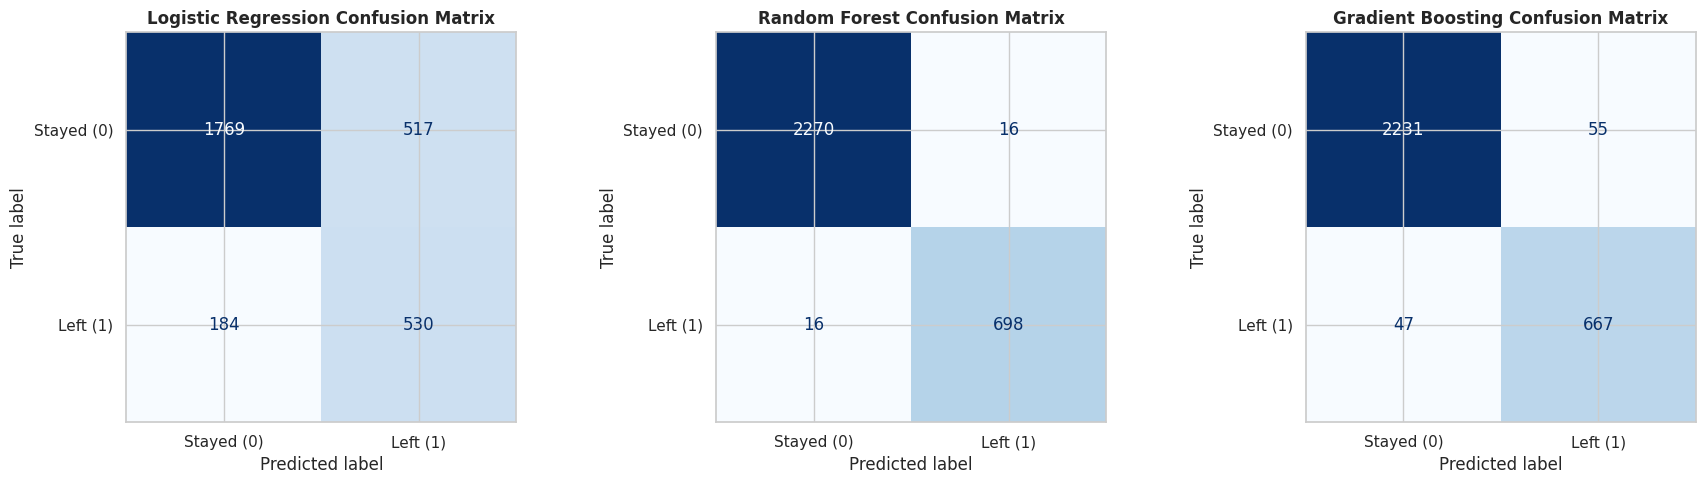


--- 6.3 METRIC JUSTIFICATION: RECALL VS PRECISION ---
For Employee Turnover prediction, RECALL is the most critical metric.
Justification: A False Negative (predicting an employee will stay when they actually leave) is highly costly to the company in terms of lost knowledge and recruitment costs. A False Positive (predicting an employee will leave when they intend to stay) only results in the company proactively checking in on a satisfied employee. Therefore, maximizing Recall minimizes the risk of sudden, unexpected turnover.

--- 7. RETENTION STRATEGIES FOR TARGETED EMPLOYEES ---
Test Data Risk Zone Distribution:
Risk_Zone
Safe Zone (Green)            2162
High-Risk Zone (Red)          646
Low-Risk Zone (Yellow)        133
Medium-Risk Zone (Orange)      59
Name: count, dtype: int64

--- SUGGESTED RETENTION STRATEGIES BY ZONE ---
1. High-Risk Zone (Red | >90%): Immediate HR intervention required. Schedule 1-on-1 retention interviews to address urgent burnout or compensation mismatch.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay

# --- 5. MODEL TRAINING & 5-FOLD CV ---
print("--- 5. MODEL TRAINING & CROSS-VALIDATION ---")
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=123),
    'Random Forest': RandomForestClassifier(random_state=123),
    'Gradient Boosting': GradientBoostingClassifier(random_state=123)
}

trained_models = {}
for name, model in models.items():
    # 5-Fold Cross Validation on the SMOTE balanced training data
    cv_scores = cross_val_score(model, X_train_sm, y_train_sm, cv=5, scoring='accuracy')
    print(f"{name} - 5-Fold CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

    # Train final model on full SMOTE dataset
    model.fit(X_train_sm, y_train_sm)
    trained_models[name] = model

    # Predictions & Classification Report
    y_pred = model.predict(X_test)
    print(f"\nClassification Report for {name}:")
    print(classification_report(y_test, y_pred))
    print("-" * 60)

# --- 6. IDENTIFY BEST MODEL & JUSTIFY METRICS ---
print("--- 6. MODEL EVALUATION & METRIC JUSTIFICATION ---")
plt.figure(figsize=(10, 7))

# 6.1 Plot ROC Curves and calculate AUC
best_model_name = None
best_auc = 0

for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    if roc_auc > best_auc:
        best_auc = roc_auc
        best_model_name = name

    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves', fontweight='bold')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"\nBest Model Identified: {best_model_name} (Highest AUC: {best_auc:.4f})")

# 6.2 Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Stayed (0)', 'Left (1)'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f'{name} Confusion Matrix', fontweight='bold')
plt.tight_layout()
plt.show()

# 6.3 Metric Justification
print("\n--- 6.3 METRIC JUSTIFICATION: RECALL VS PRECISION ---")
print("For Employee Turnover prediction, RECALL is the most critical metric.")
print("Justification: A False Negative (predicting an employee will stay when they actually leave) is highly costly to the company "
      "in terms of lost knowledge and recruitment costs. A False Positive (predicting an employee will leave when they intend to stay) "
      "only results in the company proactively checking in on a satisfied employee. Therefore, maximizing Recall minimizes the risk of sudden, unexpected turnover.")

# --- 7. RETENTION STRATEGIES (RISK ZONES) ---
print("\n--- 7. RETENTION STRATEGIES FOR TARGETED EMPLOYEES ---")
best_model = trained_models[best_model_name]
# 7.1 Predict probabilities on test data
test_probs = best_model.predict_proba(X_test)[:, 1] * 100 # Convert to percentage

# 7.2 Categorize into Risk Zones
test_results = pd.DataFrame({'Actual': y_test, 'Turnover_Probability': test_probs})

conditions = [
    (test_results['Turnover_Probability'] < 20),
    (test_results['Turnover_Probability'] >= 20) & (test_results['Turnover_Probability'] < 60),
    (test_results['Turnover_Probability'] >= 60) & (test_results['Turnover_Probability'] <= 90),
    (test_results['Turnover_Probability'] > 90)
]
choices = ['Safe Zone (Green)', 'Low-Risk Zone (Yellow)', 'Medium-Risk Zone (Orange)', 'High-Risk Zone (Red)']

# Added default='Unknown' to resolve the NumPy string dtype promotion error
test_results['Risk_Zone'] = np.select(conditions, choices, default='Unknown')

print("Test Data Risk Zone Distribution:")
print(test_results['Risk_Zone'].value_counts())

print("\n--- SUGGESTED RETENTION STRATEGIES BY ZONE ---")
print("1. High-Risk Zone (Red | >90%): Immediate HR intervention required. Schedule 1-on-1 retention interviews to address urgent burnout or compensation mismatch. Offer immediate workload relief or title adjustments.")
print("2. Medium-Risk Zone (Orange | 60-90%): Proactive engagement. Review their current project count (check for 6+ projects indicating burnout or 2 indicating underutilization). Discuss career development paths and upcoming raise cycles.")
print("3. Low-Risk Zone (Yellow | 20-60%): Passive monitoring. Send standard quarterly employee satisfaction surveys and ensure they are taking their allocated PTO.")
print("4. Safe Zone (Green | <20%): Baseline engagement. Recognize their loyalty through standard performance bonuses and use them as culture benchmarks for new hires.")